### Production decision

A company produces two products, A and B. Each unit of A requires 2.5 hours of labor and 1 hour of machine time. Each unit of B requires 1 hour of labor and 2 hours of machine time. The company has 40 hours of labor and 50 hours of machine time available. 

The profit per unit of A is $\$5$, and the profit per unit of B is \$7. 

How many units of A and B should the company produce to maximize profit?

In [1]:
library(lpSolve)

In [6]:
# xA = # of product A to produce
# xB = # of product B to produce
# z is your profit, which you want to maximize
# z = 5*xA + 6*xB

# Define the objective function coefficients (maximizing profit)
f.z <- c(5, 7)


# Define the constraints matrix
#  2*xA + 1*xB <= 40  (labor)
#  1*xA + 2*xB <= 50  (machine)
f.C <- matrix(c(2.5, 1,
                1  , 2),
              nrow = 2, byrow = TRUE)

# Define the direction of the constraints
f.dir <- c("<=", "<=")

# Define the right-hand side of the constraints
f.rhs <- c(40, 50)


# Solve the linear program to maximize profit
solution <- lp("max", f.z, f.C, f.dir, f.rhs,   all.int=FALSE)

# Print the solution
print(solution)

cat("Optimal Units (A, B):", solution$solution, "\n")
cat("Maximum Profit: $", solution$objval, "\n")


Success: the objective function is 186.25 
Optimal Units (A, B): 7.5 21.25 
Maximum Profit: $ 186.25 


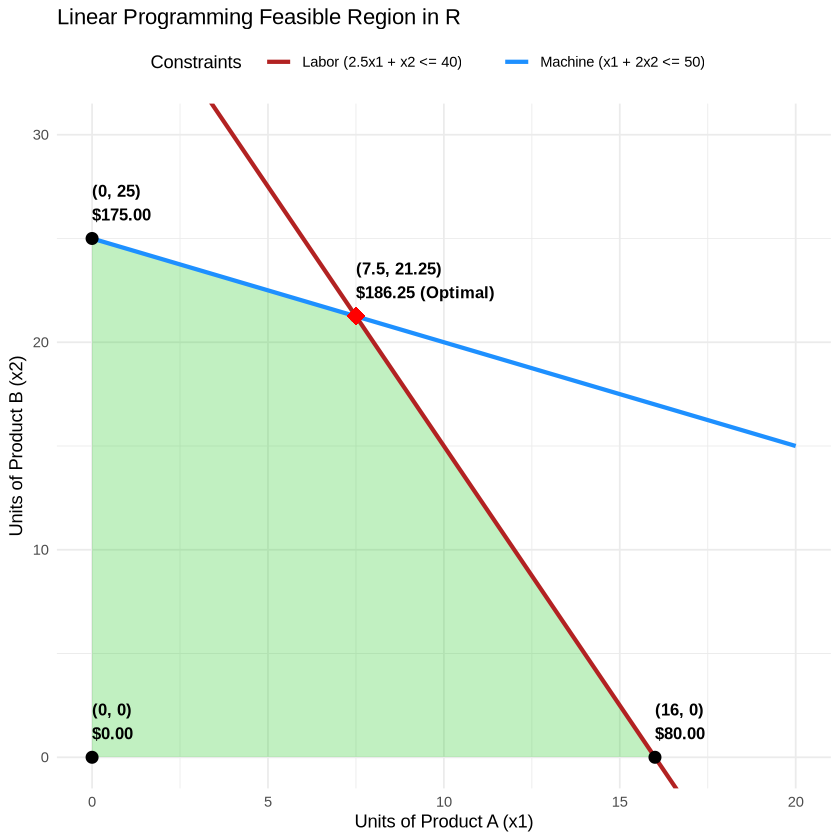

In [3]:
library(ggplot2)

# 1. Create data frame for constraint lines
x1_vals <- seq(0, 20, length.out = 300)

df_lines <- data.frame(
  x1 = rep(x1_vals, 2),
  x2 = c(40 - 2.5 * x1_vals,       # Labor: 2.5*x1 + x2 = 40
         (50 - x1_vals) / 2),      # Machine: x1 + 2*x2 = 50
  Constraint = rep(c("Labor (2.5x1 + x2 <= 40)", 
                     "Machine (x1 + 2x2 <= 50)"), each = 300)
)

# 2. Define vertices of the bounded feasible region polygon
polygon_df <- data.frame(
  x1 = c(0, 16, 7.5, 0),
  x2 = c(0, 0, 21.25, 25)
)

# 3. Define corner points with profit values
corners_df <- data.frame(
  x1 = c(0, 16, 0, 7.5),
  x2 = c(0, 0, 25, 21.25),
  label = c("(0, 0)\n$0.00", "(16, 0)\n$80.00", 
            "(0, 25)\n$175.00", "(7.5, 21.25)\n$186.25 (Optimal)")
)

# 4. Build ggplot visualization
ggplot() +
  # Feasible Region Shading
  geom_polygon(data = polygon_df, aes(x = x1, y = x2), 
               fill = "limegreen", alpha = 0.3) +
  
  # Constraint Lines
  geom_line(data = df_lines, aes(x = x1, y = x2, color = Constraint), 
            linewidth = 1.2) +
  
  # Corner Vertices & Annotations
  geom_point(data = corners_df, aes(x = x1, y = x2), 
             size = 3, color = "black") +
  geom_point(data = subset(corners_df, x1 == 7.5), aes(x = x1, y = x2), 
             size = 5, color = "red", shape = 18) +
  geom_text(data = corners_df, aes(x = x1, y = x2, label = label), 
            vjust = -0.5, hjust = 0, size = 3.5, fontface = "bold") +
  
  # Formatting & Labels
  scale_color_manual(values = c("firebrick", "dodgerblue")) +
  coord_cartesian(xlim = c(0, 20), ylim = c(0, 30)) +
  labs(
    title = "Linear Programming Feasible Region in R",
    x = "Units of Product A (x1)",
    y = "Units of Product B (x2)",
    color = "Constraints"
  ) +
  theme_minimal() +
  theme(legend.position = "top")

### Guard Duty (Work scheduling) Problem

Security is broken in to six 4 hour time blocks (12-4am, 4-8am, ..., 8pm-12am)

Guards work 8 hour shifts, which must be two consecutive blocks.

The number of guards needed in each block are 10,8,7,6,9,5 respectively.

In [7]:
# x1 = # of guards coming on duty block 1
# x2 = # of guards coming on duty block 2
# x3 = # of guards coming on duty block 3
# x4 = # of guards coming on duty block 4
# x5 = # of guards coming on duty block 5
# x6 = # of guards coming on duty block 6
# z is total number of guard shifts
# z = x1 + x2 + x3 + x4 + x5 + x6

# Define the objective function coefficients (minimize shifts)
f.z <- c(1,1,1,1,1,1)


# Define the constraints
#  x6 + x1 >= 10      
#  x1 + x2 >= 8
#  x2 + x3 >= 7
#  x3 + x4 >= 6
#  x4 + x5 >= 9
#  x5 + x6 >= 5
f.C <- matrix(c(1,0,0,0,0,1,
                1,1,0,0,0,0,
                0,1,1,0,0,0,
                0,0,1,1,0,0,
                0,0,0,1,1,0,
                0,0,0,0,1,1),
              nrow = 6, byrow = TRUE)
f.dir <- c(">=", ">=",">=",">=",">=",">=")
f.rhs <- c(10,8,7,6,9,5)

# Solve the linear program to minimize cost
solution <- lp("min", f.z, f.C, f.dir, f.rhs, all.int=TRUE)

# print the solution
print(solution)
solution$solution
solution$objval


Success: the objective function is 26 


[1] 10  5  2  4  5  0

[1] 26

In [8]:
#How would it change if graveyard shift workers (8pm-4am) get paid 20% more ?

# shifts weighted by pay
f.z <- c(1.2,1,1,1,1.2,1.2)

solution <- lp("min", f.z, f.C, f.dir, f.rhs, all.int=TRUE)


# print the solution
print(solution)
solution$solution
solution$objval

Success: the objective function is 28 


[1] 5 3 4 9 0 5

[1] 28

## Multi-Channel Media Ad Spend Optimization with Diminishing Marginal Returns.

Marketing teams face a classic continuous linear programming problem: how to allocate a fixed advertising budget across channels (e.g., Search, Social, TV) when each channel has a different expected cost-per-acquisition (CPA), audience exposure cap, and strategic policy constraint.

Because advertising returns diminish as spend increases, we handle non-linear curves in LP by piecewise linearization (breaking ad spend into tiered response buckets with progressively lower ROI).

Have A.I. provide details for such a problem, and show you how to solve it with R lpsolve